# Incendios en el Perú · Últimos 60 días

**Objetivo:** identificar las zonas del Perú más afectadas por incendios de vegetación entre el
29 de agosto y el 27 de octubre de 2026, y caracterizar qué tipo de cobertura se quemó.

| | |
|---|---|
| **Periodo** | 29 de agosto – 27 de octubre de 2026 (60 días; fecha de corte: 27/10) |
| **Cobertura** | Todo el Perú, focos de calor VIIRS de confianza nominal o alta |
| **Nivel** | Departamento, distrito y área natural protegida (ANP) |

**Fuentes**

| Dato | Fuente |
|---|---|
| Focos de calor (375 m) | NASA FIRMS — VIIRS S-NPP, NOAA-20 y NOAA-21, versión NRT |
| Cobertura del suelo (10 m) | ESA WorldCover 2021 v200 |
| Límites distritales | INEI, vía dataset del curso en Hugging Face |
| Áreas naturales protegidas | SERNANP (copia publicada en ArcGIS Online) |

Un **foco de calor** es un píxel de 375 m donde el satélite detectó fuego en una pasada.
No es lo mismo que un incendio: un incendio grande genera muchos focos, y una quema agrícola
también aparece como foco. Por eso cruzamos cada foco con WorldCover: para saber qué se estaba quemando.

In [1]:
from pathlib import Path
import json
import urllib.request

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

CORTE = pd.Timestamp("2026-10-27")
INICIO = CORTE - pd.Timedelta(days=59)    # 60 días contando el día de corte

BBOX_PERU = "-81.4,-18.4,-68.6,0.1"   # oeste, sur, este, norte
AREA_IGUAL = "ESRI:102033"            # Albers de igual área para Sudamérica: áreas en km² correctas

CRUDOS = Path("datos/crudos")
SALIDA = Path("datos")
CRUDOS.mkdir(parents=True, exist_ok=True)

print(f"Periodo: {INICIO:%d/%m/%Y} – {CORTE:%d/%m/%Y}")

Periodo: 29/08/2026 – 27/10/2026


/Users/susanmontalvo/anaconda3/envs/raster/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Descargar los focos de FIRMS

La clave de la API (MAP_KEY) vive en `../.env`, que está en `.gitignore`: no se sube a GitHub.

Todo el periodo usa la versión **NRT** (*near real time*) de los tres satélites VIIRS.
La API entrega como máximo 5 días por consulta, así que pedimos los 60 días por tramos.
Cada descarga se guarda en `datos/crudos/`, y la segunda ejecución ya no consulta la API.

In [2]:
def leer_clave(ruta=Path("../.env")):
    for linea in ruta.read_text().splitlines():
        if linea.startswith("FIRMS_MAP_KEY="):
            return linea.split("=", 1)[1].strip()
    raise ValueError("No encontré FIRMS_MAP_KEY en ../.env")

MAP_KEY = leer_clave()

def descargar(fuente, desde, hasta, dias=5):
    """Focos de una fuente FIRMS sobre el Perú entre dos fechas (inclusive)."""
    archivo = CRUDOS / f"{fuente}_{desde:%Y%m%d}_{hasta:%Y%m%d}.csv"
    if archivo.exists():
        return pd.read_csv(archivo)
    partes = []
    for d in pd.date_range(desde, hasta, freq=f"{dias}D"):
        n = min(dias, (hasta - d).days + 1)
        url = (f"https://firms.modaps.eosdis.nasa.gov/api/area/csv/"
               f"{MAP_KEY}/{fuente}/{BBOX_PERU}/{n}/{d:%Y-%m-%d}")
        try:
            with urllib.request.urlopen(url, timeout=120) as r:
                partes.append(pd.read_csv(r))
        except Exception:
            # Sin la URL en el mensaje: llevaría la clave a la salida del notebook
            raise RuntimeError(f"Falló la descarga de {fuente} para {d:%Y-%m-%d}") from None
    df = pd.concat(partes, ignore_index=True)
    df.to_csv(archivo, index=False)
    return df

FUENTES = {"S-NPP": "VIIRS_SNPP_NRT", "NOAA-20": "VIIRS_NOAA20_NRT", "NOAA-21": "VIIRS_NOAA21_NRT"}

tablas = []
for satelite, fuente in FUENTES.items():
    df = descargar(fuente, INICIO, CORTE)
    tablas.append(df.assign(satelite=satelite))
    print(f"{satelite:<8} {len(df):>7,} focos")

crudos = pd.concat(tablas, ignore_index=True)
print(f"\nTotal en el recuadro del Perú: {len(crudos):,}")

S-NPP     52,852 focos


NOAA-20   50,684 focos


NOAA-21   48,619 focos

Total en el recuadro del Perú: 152,155


## 2. Limpiar

1. **Confianza:** quitamos los focos de confianza baja. FIRMS la escribe como `l/n/h` o
   `low/nominal/high`; nos quedamos con la primera letra.
2. **Fechas:** solo la ventana de 60 días.
3. **Duplicados:** mismo punto, satélite, fecha y hora.

In [3]:
focos = crudos.copy()
focos["confianza"] = focos["confidence"].astype(str).str[0].str.lower()
focos["fecha"] = pd.to_datetime(focos["acq_date"])

antes = len(focos)
focos = focos[focos["confianza"] != "l"]
print(f"Confianza baja:        -{antes - len(focos):,}")

antes = len(focos)
focos = focos[focos["fecha"].between(INICIO, CORTE)]
focos = focos.drop_duplicates(["latitude", "longitude", "satelite", "acq_date", "acq_time"])
print(f"Fuera de fecha/dupl.:  -{antes - len(focos):,}")
print(f"Quedan:                 {len(focos):,}")

Confianza baja:        -11,745
Fuera de fecha/dupl.:  -0
Quedan:                 140,410


## 3. Ubicar cada foco en su distrito

El recuadro de descarga incluye partes de Ecuador, Colombia, Brasil, Bolivia y Chile.
El cruce espacial con los distritos resuelve dos cosas a la vez: asigna departamento y distrito,
y descarta los focos fuera del Perú.

In [4]:
REPO = "aquiro1994/ds-python-up"

def traer_shapefile(base):
    for ext in ("dbf", "shx", "prj", "cpg"):
        hf_hub_download(REPO, f"{base}.{ext}", repo_type="dataset")
    return hf_hub_download(REPO, f"{base}.shp", repo_type="dataset")

distritos = gpd.read_file(traer_shapefile("_data/Folium/DISTRITOS"))
distritos = distritos[["IDDIST", "DEPARTAMEN", "PROVINCIA", "DISTRITO", "geometry"]]
# Las áreas se calculan en una proyección de igual área, nunca en grados (EPSG:4326)
distritos["area_km2"] = distritos.to_crs(AREA_IGUAL).area / 1e6

puntos = gpd.GeoDataFrame(
    focos, geometry=gpd.points_from_xy(focos["longitude"], focos["latitude"]), crs="EPSG:4326"
)
puntos = gpd.sjoin(puntos, distritos.drop(columns="area_km2"), predicate="within", how="inner")
puntos = puntos.drop(columns="index_right").reset_index(drop=True)

print(f"Focos dentro del Perú: {len(puntos):,} de {len(focos):,}")
print(f"Distritos con al menos un foco: {puntos['IDDIST'].nunique():,} de {len(distritos):,}")

Focos dentro del Perú: 91,954 de 140,410
Distritos con al menos un foco: 1,471 de 1,873


## 4. ¿Qué se estaba quemando? Cruce con ESA WorldCover

WorldCover clasifica cada píxel de 10 m del planeta en 11 coberturas. Está publicado como
mosaicos de 3° × 3° en formato *Cloud Optimized GeoTIFF*: cada archivo trae versiones reducidas
(*overviews*) que se pueden leer por internet sin bajar el archivo completo.

**Decisión de escala.** Un foco VIIRS representa un píxel de 375 m. Leemos WorldCover a 1/8 de su
resolución (≈ 80 m), así que cada huella de foco contiene unos 5 × 5 píxeles. A cada foco le
asignamos la **cobertura mayoritaria** dentro de su huella. Leer a 10 m no cambiaría el resultado
de forma apreciable y obligaría a bajar varios GB.

Agrupamos las clases en tres:

| Grupo | Clases WorldCover | Lectura |
|---|---|---|
| **Vegetación natural** | bosque, matorral, pastizal, humedal, manglar, musgo | incendio de vegetación |
| **Cultivo** | cultivos | probable quema agrícola |
| **Otro** | construido, suelo desnudo, nieve, agua | posible fuente industrial o error de ubicación |

In [5]:
CLASES = {10: "Bosque", 20: "Matorral", 30: "Pastizal", 40: "Cultivo", 50: "Construido",
          60: "Suelo desnudo", 70: "Nieve", 80: "Agua", 90: "Humedal", 95: "Manglar", 100: "Musgo"}
GRUPO = {"Bosque": "Vegetación natural", "Matorral": "Vegetación natural", "Pastizal": "Vegetación natural",
         "Humedal": "Vegetación natural", "Manglar": "Vegetación natural", "Musgo": "Vegetación natural",
         "Cultivo": "Cultivo"}

WC = "https://esa-worldcover.s3.eu-central-1.amazonaws.com"
REDUCCION = 8      # overview 1/8: ≈ 80 m por píxel
RADIO = 2          # ventana de 5 × 5 píxeles ≈ 400 m, la huella de un foco VIIRS
codigos = np.array(sorted(CLASES))

# El nombre de cada mosaico es su esquina inferior izquierda: S15W078 cubre 15–12°S, 78–75°O
puntos["mosaico"] = [
    f"{'S' if la < 0 else 'N'}{abs(int(np.floor(la / 3) * 3)):02d}"
    f"{'W' if lo < 0 else 'E'}{abs(int(np.floor(lo / 3) * 3)):03d}"
    for la, lo in zip(puntos["latitude"], puntos["longitude"])
]

puntos["cobertura"] = None
for mosaico, grupo in puntos.groupby("mosaico"):
    url = f"/vsicurl/{WC}/v200/2021/map/ESA_WorldCover_10m_2021_v200_{mosaico}_Map.tif"
    with rasterio.open(url) as src:
        alto, ancho = src.height // REDUCCION, src.width // REDUCCION
        mapa = src.read(1, out_shape=(alto, ancho))
        filas, cols = rasterio.transform.rowcol(
            src.transform * src.transform.scale(REDUCCION, REDUCCION),
            grupo["longitude"].values, grupo["latitude"].values,
        )
    filas, cols = np.asarray(filas), np.asarray(cols)
    # Para cada foco, los 25 píxeles de su ventana; luego contamos cuántos hay de cada clase
    d = np.arange(-RADIO, RADIO + 1)
    f = np.clip(filas[:, None, None] + d[None, :, None], 0, alto - 1)
    c = np.clip(cols[:, None, None] + d[None, None, :], 0, ancho - 1)
    ventana = mapa[f, c].reshape(len(grupo), -1)
    conteos = (ventana[:, :, None] == codigos[None, None, :]).sum(axis=1)
    mayoritaria = codigos[conteos.argmax(axis=1)]
    puntos.loc[grupo.index, "cobertura"] = [CLASES[k] for k in mayoritaria]
    print(f"{mosaico}: {len(grupo):>6,} focos")

puntos["grupo"] = puntos["cobertura"].map(GRUPO).fillna("Otro")
puntos["vegetacion"] = puntos["grupo"] == "Vegetación natural"

print()
print(puntos["grupo"].value_counts(normalize=True).mul(100).round(1).astype(str) + " %")

S03W072:      5 focos


S03W075:     68 focos


S03W078:     28 focos


S06W072:    997 focos


S06W075:  1,112 focos


...

S15W078:  1,640 focos


S18W069:      2 focos


S18W072:  2,837 focos


S18W075:  1,034 focos


S18W078:     20 focos

grupo
Vegetación natural    96.5 %
Otro                   2.1 %
Cultivo                1.5 %
Name: proportion, dtype: str


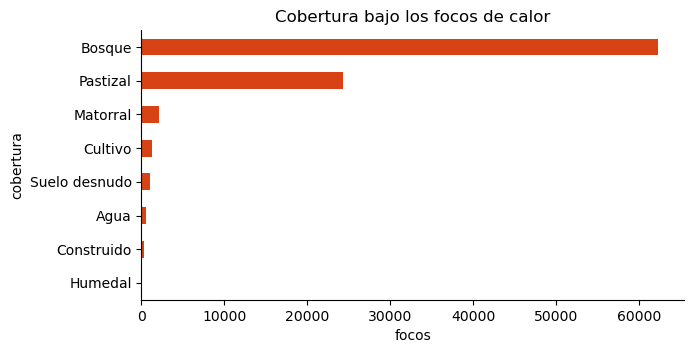

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
puntos["cobertura"].value_counts().sort_values().plot.barh(ax=ax, color="#d84315")
ax.set_xlabel("focos")
ax.set_title("Cobertura bajo los focos de calor")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 5. Áreas naturales protegidas

Usamos las ANP **nacionales** y **regionales**. Dejamos fuera las privadas: son muchas y pequeñas,
y con píxeles de 375 m un foco en su borde puede caer dentro o fuera por azar.
Algunas ANP tienen varios polígonos (por ejemplo, islas), así que las unimos por nombre.

In [7]:
archivo_anp = CRUDOS / "anp.geojson"
if not archivo_anp.exists():
    urllib.request.urlretrieve(
        "https://services.arcgis.com/iQ1dY19aHwbSDYIF/arcgis/rest/services/Areas_naturales_protegidas"
        "/FeatureServer/0/query?where=1%3D1&outFields=*&outSR=4326&f=geojson",
        archivo_anp,
    )

anp = gpd.read_file(archivo_anp)
anp = anp[anp["Clase"].isin(["ANP Nacional", "ANP Regional"])].copy()
anp["nombre"] = anp["ANP_NOMB"].str.strip()
anp["categoria"] = anp["ANP_CATE"].str.strip()
anp = anp.dissolve(by=["nombre", "categoria", "Clase"], as_index=False)[["nombre", "categoria", "Clase", "geometry"]]
anp["area_km2"] = anp.to_crs(AREA_IGUAL).area / 1e6

en_anp = gpd.sjoin(puntos[["geometry"]], anp[["nombre", "geometry"]], predicate="within", how="inner")
puntos["anp"] = en_anp.groupby(level=0)["nombre"].first()

print(f"{len(anp)} ANP (nacionales y regionales)")
print(f"Focos dentro de una ANP: {puntos['anp'].notna().sum():,} "
      f"({puntos['anp'].notna().mean():.1%} del total)")

100 ANP (nacionales y regionales)
Focos dentro de una ANP: 1,158 (1.3% del total)


## 6. ¿Qué zonas fueron las más afectadas?

El criterio principal son los **focos en vegetación natural**: los que WorldCover ubica sobre bosque,
matorral, pastizal o humedal. Así el ranking mide incendios de vegetación y no quemas agrícolas.

Lo medimos de dos formas:

- **Focos totales:** cuánto fuego hubo. Favorece a los distritos grandes.
- **Focos por 100 km²:** qué tan concentrado estuvo. Corrige el tamaño, pero un distrito pequeño
  con pocos focos puede salir arriba; por eso exigimos al menos 20 focos.

Y añadimos los **focos de los últimos 7 días** para ver dónde sigue activo.

In [8]:
ULTIMA_SEMANA = CORTE - pd.Timedelta(days=6)
puntos["ultima_semana"] = puntos["fecha"] >= ULTIMA_SEMANA

def resumir(df, por):
    r = df.groupby(por).agg(
        focos=("geometry", "size"),
        focos_veg=("vegetacion", "sum"),
        focos_cultivo=("grupo", lambda g: (g == "Cultivo").sum()),
        frp_mw=("frp", "sum"),
        focos_7d=("ultima_semana", "sum"),
        focos_en_anp=("anp", "count"),
    ).reset_index()
    # Cobertura principal de lo que ardió en vegetación natural
    principal = df[df["vegetacion"]].groupby(por)["cobertura"].agg(lambda s: s.value_counts().index[0])
    return r.merge(principal.rename("cobertura_principal").reset_index(), on=por, how="left")

r_dist = resumir(puntos, ["IDDIST", "DEPARTAMEN", "PROVINCIA", "DISTRITO"])
r_dist = r_dist.merge(distritos[["IDDIST", "area_km2"]], on="IDDIST")
r_dist["veg_100km2"] = r_dist["focos_veg"] / r_dist["area_km2"] * 100
r_dist = r_dist.sort_values("focos_veg", ascending=False)

area_dep = distritos.groupby("DEPARTAMEN")["area_km2"].sum()
r_dep = resumir(puntos, ["DEPARTAMEN"]).merge(area_dep, on="DEPARTAMEN")
r_dep["veg_100km2"] = r_dep["focos_veg"] / r_dep["area_km2"] * 100
r_dep["pct_veg"] = r_dep["focos_veg"] / r_dep["focos"] * 100
r_dep = r_dep.sort_values("focos_veg", ascending=False)

r_anp = resumir(puntos.dropna(subset=["anp"]), ["anp"]).rename(columns={"anp": "nombre"})
r_anp = r_anp.drop(columns="focos_en_anp").merge(anp[["nombre", "categoria", "Clase", "area_km2"]], on="nombre")
r_anp["veg_100km2"] = r_anp["focos_veg"] / r_anp["area_km2"] * 100
r_anp = r_anp.sort_values("focos_veg", ascending=False)

r_dep[["DEPARTAMEN", "focos", "focos_veg", "pct_veg", "veg_100km2", "focos_7d", "cobertura_principal"]].head(10).round(1)

,DEPARTAMEN,focos,focos_veg,pct_veg,veg_100km2,focos_7d,cobertura_principal
24,UCAYALI,17739,17608,99.3,16.7,856,Bosque
21,SAN MARTIN,11268,11055,98.1,21.7,265,Bosque
9,HUANUCO,10695,10642,99.5,28.4,232,Bosque
15,LORETO,8464,8148,96.3,2.2,611,Bosque
11,JUNIN,7691,7526,97.9,17.0,135,Bosque
16,MADRE DE DIOS,6179,6156,99.6,7.3,461,Bosque
7,CUSCO,5051,4935,97.7,6.9,95,Pastizal
2,APURIMAC,2954,2929,99.2,13.9,24,Pastizal
5,CAJAMARCA,2945,2866,97.3,8.7,113,Pastizal
18,PASCO,2582,2579,99.9,10.8,101,Bosque


In [9]:
cols = ["DEPARTAMEN", "PROVINCIA", "DISTRITO", "focos_veg", "veg_100km2", "focos_cultivo", "focos_7d", "cobertura_principal"]
print("Distritos con más focos en vegetación natural")
display(r_dist[cols].head(10).round(1))

print("Distritos con más focos en vegetación por 100 km² (mínimo 20 focos)")
display(r_dist[r_dist["focos_veg"] >= 20].sort_values("veg_100km2", ascending=False)[cols].head(10).round(1))

Distritos con más focos en vegetación natural


,DEPARTAMEN,PROVINCIA,DISTRITO,focos_veg,veg_100km2,focos_cultivo,focos_7d,cobertura_principal
1461,UCAYALI,ATALAYA,RAIMONDI,2653,18.2,0,119,Bosque
1459,UCAYALI,CORONEL PORTILLO,NUEVA REQUENA,2612,126.7,0,82,Bosque
767,HUANUCO,PUERTO INCA,PUERTO INCA,2022,84.6,0,27,Bosque
890,JUNIN,SATIPO,RIO TAMBO,1899,18.6,0,45,Bosque
892,JUNIN,SATIPO,MAZAMARI - PANGOA,1762,31.0,0,45,Bosque
1466,UCAYALI,PADRE ABAD,IRAZOLA,1673,89.1,0,25,Bosque
1457,UCAYALI,CORONEL PORTILLO,MASISEA,1556,10.6,0,158,Bosque
770,HUANUCO,PUERTO INCA,TOURNAVISTA,1525,87.6,0,25,Bosque
1467,UCAYALI,PADRE ABAD,CURIMANA,1522,81.0,1,32,Bosque
1363,SAN MARTIN,BELLAVISTA,ALTO BIAVO,1505,25.3,1,17,Bosque


Distritos con más focos en vegetación por 100 km² (mínimo 20 focos)


,DEPARTAMEN,PROVINCIA,DISTRITO,focos_veg,veg_100km2,focos_cultivo,focos_7d,cobertura_principal
199,APURIMAC,ABANCAY,SAN PEDRO DE CACHORA,193,163.7,0,0,Pastizal
178,ANCASH,SIHUAS,SIHUAS,73,158.6,0,0,Pastizal
1459,UCAYALI,CORONEL PORTILLO,NUEVA REQUENA,2612,126.7,0,82,Bosque
858,JUNIN,JAUJA,EL MANTARO,20,111.7,2,0,Pastizal
195,APURIMAC,ABANCAY,CURAHUASI,960,111.7,6,14,Pastizal
1365,SAN MARTIN,BELLAVISTA,HUALLAGA,268,104.0,2,9,Bosque
1458,UCAYALI,CORONEL PORTILLO,YARINACOCHA,678,102.4,0,140,Bosque
368,AYACUCHO,HUANTA,CHACA,98,92.5,0,0,Pastizal
1466,UCAYALI,PADRE ABAD,IRAZOLA,1673,89.1,0,25,Bosque
770,HUANUCO,PUERTO INCA,TOURNAVISTA,1525,87.6,0,25,Bosque


In [10]:
print("ANP con más focos en vegetación natural")
r_anp[["nombre", "categoria", "focos_veg", "veg_100km2", "focos_7d", "cobertura_principal"]].head(10).round(1)

ANP con más focos en vegetación natural


,nombre,categoria,focos_veg,veg_100km2,focos_7d,cobertura_principal
22,Sub Cuenca del Cotahuasi,Reserva Paisajistica,310,6.3,0,Pastizal
7,El Sira,Reserva Comunal,190,3.1,4,Bosque
8,Huascarán,Parque Nacional,165,4.9,0,Pastizal
16,Pacaya Samiria,Reserva Nacional,116,0.5,7,Bosque
14,Nor Yauyos-Cochas,Reserva Paisajistica,96,4.3,2,Pastizal
18,Reserva Paisajística Cerro Khapia,Zona Reservada,65,35.5,0,Pastizal
12,Machupicchu,Santuario Histórico,39,10.5,0,Pastizal
21,Sierra del Divisor,Zona Reservada,33,0.2,4,Bosque
24,Tambopata,Reserva Nacional,19,0.7,7,Bosque
29,del Manu,Parque Nacional,11,0.1,0,Bosque


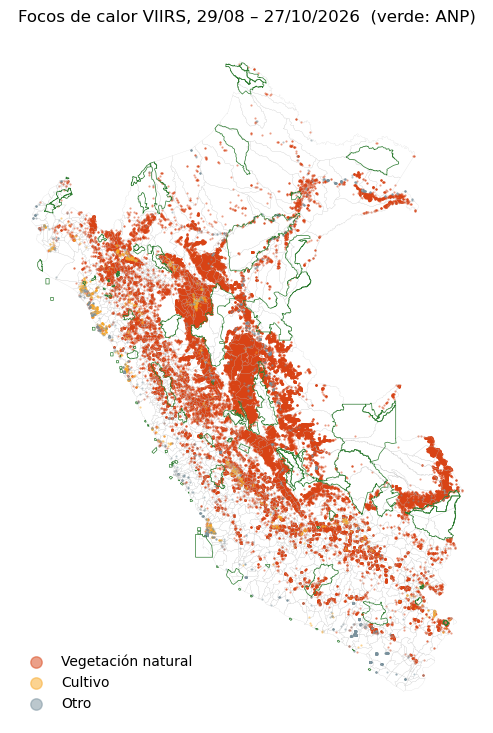

In [11]:
COLOR_GRUPO = {"Vegetación natural": "#d84315", "Cultivo": "#f9a825", "Otro": "#78909c"}

fig, ax = plt.subplots(figsize=(7, 9))
distritos.boundary.plot(ax=ax, linewidth=0.1, color="#bbbbbb")
anp.boundary.plot(ax=ax, linewidth=0.5, color="#2e7d32")
for grupo, color in COLOR_GRUPO.items():
    sel = puntos[puntos["grupo"] == grupo]
    ax.scatter(sel["longitude"], sel["latitude"], s=0.3, color=color, alpha=0.5, label=grupo)
ax.legend(markerscale=15, loc="lower left", frameon=False)
ax.set_title(f"Focos de calor VIIRS, {INICIO:%d/%m} – {CORTE:%d/%m/%Y}  (verde: ANP)")
ax.set_axis_off()
plt.show()

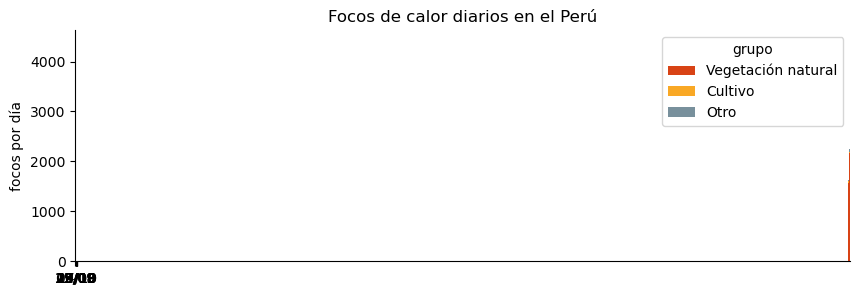

In [12]:
serie = (puntos.groupby(["fecha", "grupo"]).size().unstack(fill_value=0)
         .reindex(pd.date_range(INICIO, CORTE), fill_value=0)
         .reindex(columns=list(COLOR_GRUPO), fill_value=0))

fig, ax = plt.subplots(figsize=(10, 3))
serie.plot.bar(stacked=True, ax=ax, width=1, color=list(COLOR_GRUPO.values()))
ax.set_xticks(range(0, len(serie), 7), [f"{d:%d/%m}" for d in serie.index[::7]], rotation=0)
ax.set_ylabel("focos por día")
ax.set_title("Focos de calor diarios en el Perú")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Cómo leer estos resultados.** Hay dos paisajes del fuego:

- **Selva** (Ucayali, San Martín, Huánuco, Loreto, Junín): concentra la mayoría de los focos, casi todos
  sobre lo que en 2021 era bosque. Es el patrón de la roza y quema en la frontera agrícola.
- **Sierra** (Cusco, Apurímac, Cajamarca, Áncash): menos focos en total, pero con las densidades más altas
  por km² en distritos pequeños, sobre pastizal. Es el patrón de la quema de pastos que se sale de control.

Las ANP reciben pocos focos en proporción, pero las más afectadas son sobre todo andinas y de pastizal
(Cotahuasi, Huascarán, Nor Yauyos-Cochas), junto con El Sira en la selva.

## 7. Exportar para el dashboard

Guardamos las tablas en `datos/` y un archivo compacto con todo lo que necesita el dashboard.
Luego insertamos esos datos en `dashboard_plantilla.html` para producir `dashboard.html`,
que se abre con doble clic y no necesita servidor.

In [13]:
r_dist.round(2).to_csv(SALIDA / "ranking_distritos.csv", index=False)
r_dep.round(2).to_csv(SALIDA / "ranking_departamentos.csv", index=False)
r_anp.round(2).to_csv(SALIDA / "ranking_anp.csv", index=False)
serie.rename_axis("fecha").to_csv(SALIDA / "serie_diaria.csv")
puntos[["latitude", "longitude", "fecha", "acq_time", "satelite", "confianza", "frp", "cobertura", "grupo",
        "DEPARTAMEN", "PROVINCIA", "DISTRITO", "anp"]].to_csv(SALIDA / "focos_limpios.csv", index=False)

def geojson(gdf, tolerancia):
    g = gdf.copy()
    g["geometry"] = g.geometry.simplify(tolerancia, preserve_topology=True)
    return json.loads(g.to_json(drop_id=True))

def registros(df, columnas):
    return json.loads(df[columnas].round(1).to_json(orient="records", force_ascii=False))

departamentos = distritos.dissolve(by="DEPARTAMEN", as_index=False)[["DEPARTAMEN", "geometry"]]
departamentos = departamentos.merge(r_dep, on="DEPARTAMEN", how="left")
num = departamentos.select_dtypes("number").columns
departamentos[num] = departamentos[num].fillna(0)

anp_mapa = anp.merge(r_anp[["nombre", "focos_veg", "veg_100km2", "focos_7d"]], on="nombre", how="left")
anp_mapa[["focos_veg", "veg_100km2", "focos_7d"]] = anp_mapa[["focos_veg", "veg_100km2", "focos_7d"]].fillna(0)

cols_zona = ["focos", "focos_veg", "focos_cultivo", "veg_100km2", "frp_mw", "focos_7d", "cobertura_principal"]
orden_grupos = list(COLOR_GRUPO)
nombres_cob = list(CLASES.values())
coberturas = puntos.groupby(["grupo", "cobertura"]).size().rename("focos").reset_index()

datos = {
    "inicio": f"{INICIO:%Y-%m-%d}",
    "corte": f"{CORTE:%Y-%m-%d}",
    "resumen": {
        "focos": int(len(puntos)),
        "focos_veg": int(puntos["vegetacion"].sum()),
        "focos_cultivo": int((puntos["grupo"] == "Cultivo").sum()),
        "distritos_veg": int(puntos.loc[puntos["vegetacion"], "IDDIST"].nunique()),
        "en_anp": int(puntos["anp"].notna().sum()),
        "anp_afectadas": int(puntos["anp"].nunique()),
        "ultima_semana": int(puntos["ultima_semana"].sum()),
    },
    # Puntos como columnas planas para que el archivo pese menos
    "puntos": {
        "lat": puntos["latitude"].round(3).tolist(),
        "lon": puntos["longitude"].round(3).tolist(),
        "dia": (puntos["fecha"] - INICIO).dt.days.astype(int).tolist(),
        "grupo": puntos["grupo"].map(orden_grupos.index).tolist(),
        "cob": puntos["cobertura"].map(nombres_cob.index).tolist(),
    },
    "grupos": orden_grupos,
    "nombres_cob": nombres_cob,
    "coberturas": registros(coberturas.sort_values("focos", ascending=False), ["grupo", "cobertura", "focos"]),
    "serie": {g: serie[g].astype(int).tolist() for g in orden_grupos},
    "distritos": registros(r_dist[r_dist["focos_veg"] >= 5].head(300),
                           ["DEPARTAMEN", "PROVINCIA", "DISTRITO", "area_km2", "focos_en_anp", *cols_zona]),
    "anps": registros(r_anp[r_anp["focos_veg"] > 0], ["nombre", "categoria", "Clase", *cols_zona]),
    "departamentos": geojson(departamentos[["DEPARTAMEN", "pct_veg", "focos_en_anp", *cols_zona, "geometry"]].round(1), 0.01),
    "anp": geojson(anp_mapa[["nombre", "categoria", "focos_veg", "veg_100km2", "focos_7d", "geometry"]].round(1), 0.005),
}

plantilla = Path("dashboard_plantilla.html").read_text(encoding="utf-8")
Path("dashboard.html").write_text(
    plantilla.replace("/*DATOS*/null", json.dumps(datos, ensure_ascii=False, separators=(",", ":"))),
    encoding="utf-8",
)
print(f"dashboard.html: {Path('dashboard.html').stat().st_size / 1e6:.1f} MB")

dashboard.html: 2.9 MB


## 8. Limitaciones

- **Foco ≠ incendio.** Un foco es un píxel con fuego en una pasada del satélite. Un mismo incendio
  aparece muchas veces (varios píxeles, varios días, tres satélites), así que los focos miden
  actividad de fuego, no número de incendios.
- **Lo que VIIRS no ve:** fuegos pequeños, bajo el dosel del bosque o tapados por nubes y humo.
- **"Bosque" en la selva no siempre es incendio forestal.** WorldCover es de 2021. Gran parte de los
  focos amazónicos (Ucayali, San Martín, Huánuco) son probablemente roza y quema: se tala el bosque y se
  quema para abrir chacras o pastos. Ese terreno todavía figura como bosque en 2021, así que la clase
  "Cultivo" subestima las quemas agrícolas. "Vegetación natural" se lee como *vegetación que ardió*,
  no como *incendio accidental*.
- **Escala.** Asignamos la cobertura mayoritaria en una ventana de ≈ 400 m leída a ≈ 80 m;
  en paisajes mezclados (chacras junto a pastizal) la clase asignada puede no ser la que ardió.
- **Fuentes industriales.** La versión NRT de FIRMS no marca refinerías ni fundiciones; las
  aproximamos con la clase "Otro" de WorldCover (construido, suelo desnudo), que dejamos fuera del ranking.
- **ANP:** la capa es una copia publicada de SERNANP y tiene menos áreas regionales que el registro actual.
- **Periodo.** 60 días (29/08 – 27/10) no cubren toda la temporada: agosto queda casi fuera.
  "Más afectada" significa "con más focos de vegetación en estos 60 días", no "más que lo normal".

## 9. Siguientes pasos

- **Sentinel-2 y dNBR:** medir el área quemada y su severidad en 2 o 3 incendios de las zonas más afectadas.
- **Modelo de elevación:** altitud de cada foco, para ver cuántos afectaron cabeceras de cuenca (más de 3,800 m).
- **Historia 2012–2025 con S-NPP:** comparar estos 60 días con el mismo periodo de años anteriores.
- **Agrupar focos en incendios:** focos vecinos en espacio y tiempo como un solo evento.